In [1]:
library(edgeR)
library(stringr)
library(ggplot2)
library(ggpubr)
library(data.table)
library(dplyr)

载入需要的程辑包：limma

Warning message:
“程辑包‘ggplot2’是用R版本4.1.3 来建造的”

载入程辑包：‘dplyr’


The following objects are masked from ‘package:data.table’:

    between, first, last


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




In [2]:
eg_df =read.csv('eGene_prioritization.csv',row.names = 1)
eg = rownames(eg_df)

# PBMC T-cell bulk RNA-seq

In [3]:
df = read.table('GSE111876_ReadCount.txt',row.names = 1)

In [4]:
df$gene = str_split_fixed(rownames(df),'\\.',2)[,1]
df = df[!duplicated(df$gene),]
rownames(df) = df$gene
df = df[,1:49]

In [5]:
qc = df
x <- cpm(qc, log = TRUE, prior.count = 1)
x <- t(scale(t(x)))

re = intersect(eg,rownames(x))
X = x[re,]*eg_df[re,]$weight
X <- as.matrix(t(X))

score <- rowMeans(X, na.rm=TRUE)

In [6]:
meta = read.csv('meta_final.csv')
rownames(meta) = meta$ID
sd = data.frame(score)
sd = cbind(sd,meta)

sd$Disease = 'T1D'
sd[sd$condition == 'Nondiabetic','Disease'] = 'HC'

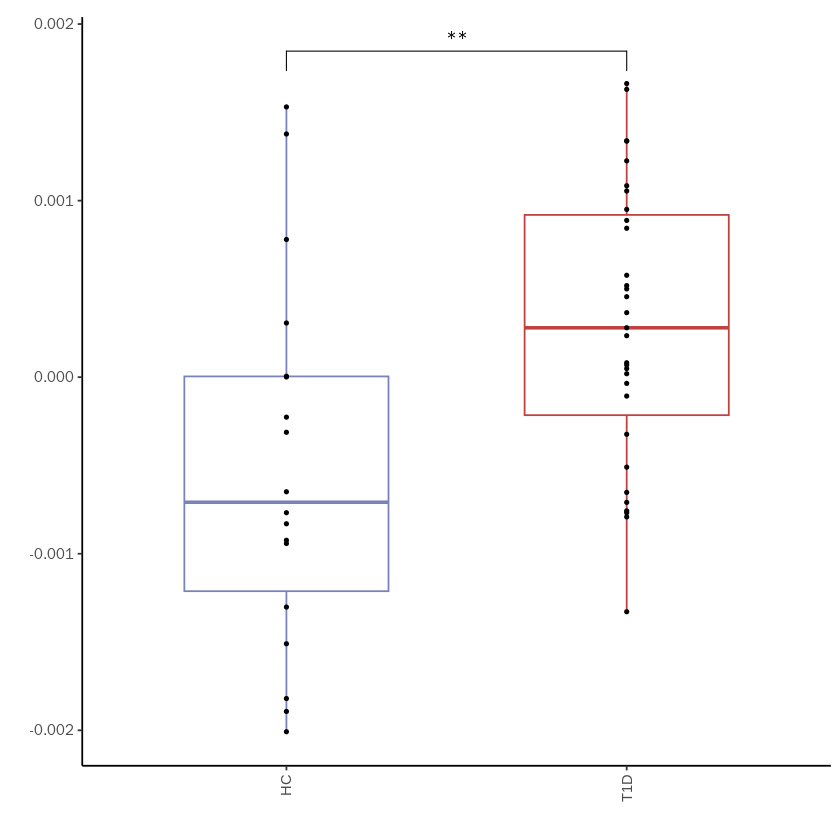

In [7]:
p1 <- ggplot(sd, aes(factor(Disease), score,color = factor(Disease))) +
  geom_boxplot(position = position_dodge(width = 0.75), width = 0.6)+
geom_jitter(width = 0, alpha = 1, size = 0.8,color = 'black')+
theme_classic()+scale_color_manual(values = c('#7883BA','#C04140'))+
theme(aspect.ratio = 1,panel.grid = element_blank(),
       axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1),
    legend.position = "None",
  )+labs(x = '',y='')+stat_compare_means(comparisons = list(c('HC','T1D')),
                       method = "t.test", label = "p.signif") 
p1

# islet T cells

In [8]:
pb_counts = read.csv('islet_T_cell_pesudobulk.csv',row.names = 1)
qc = pb_counts 
x <- cpm(qc, log = TRUE, prior.count = 1)
x <- t(scale(t(x)))

re = intersect(eg,rownames(x))

In [9]:
X = x[re,]*eg_df[re,]$weight
X <- as.matrix(t(X))
score <- rowMeans(X, na.rm=TRUE)

In [10]:
meta = read.csv('islet_meta.csv',row.names = 1)
rownames(meta) <- meta$sample

In [11]:
sd = data.frame(score)
rownames(sd) <- gsub("\\.", "-",rownames(sd))
sd$Disease =  meta[rownames(sd),]$Disease

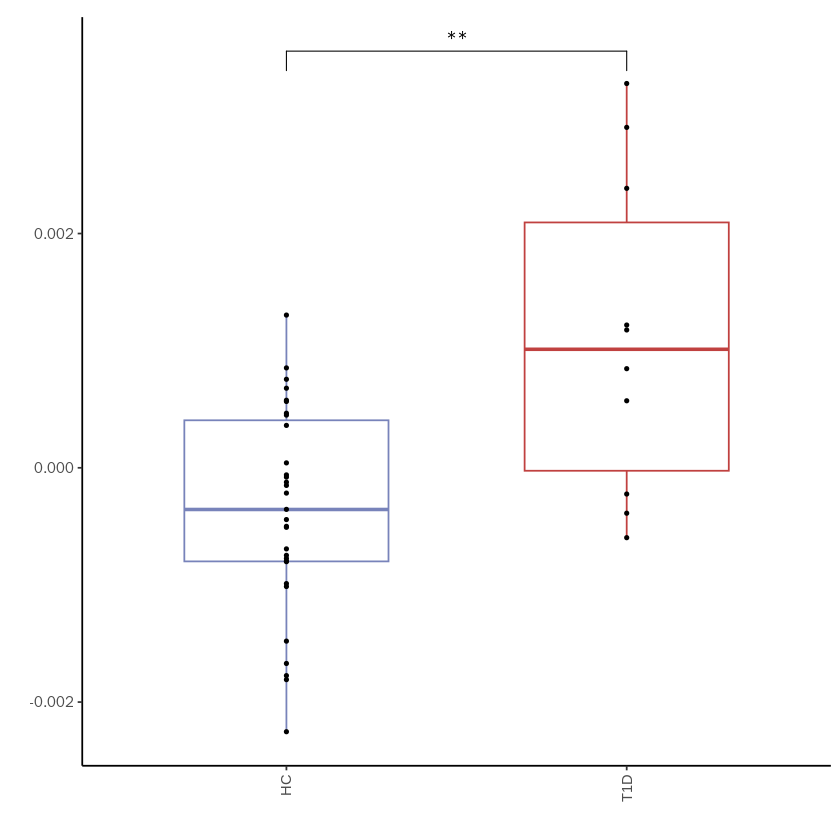

In [12]:
p2 <- ggplot(sd, aes(factor(Disease), score,color = factor(Disease))) +
  geom_boxplot(position = position_dodge(width = 0.75), width = 0.6)+
geom_jitter(width = 0, alpha = 1, size = 0.8,color = 'black')+
theme_classic()+scale_color_manual(values = c('#7883BA','#C04140'))+
theme(aspect.ratio = 1,panel.grid = element_blank(),
       axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1),
    legend.position = "None",
  )+labs(x = '',y='')+stat_compare_means(comparisons = list(c('HC','T1D')),
                       method = "t.test", label = "p.signif") 
p2

# longitudinal cohort

In [ ]:
# data pre-processing
'''
library(oligo)
library(data.table)
library(hugene21sttranscriptcluster.db)
library(AnnotationDbi)
celfiles <- list.files("GSE43488", full = TRUE)
rawData <- read.celfiles(celfiles)
eset <- rma(rawData)
expr_matrix <- exprs(eset)
an <-data.frame(fread("./GPL13667-15572.txt",header = TRUE))
an = an[an$Gene.Symbol != "---",]
rownames(an) = an$ID
keep = intersect(rownames(expr_matrix),an$ID)
expr_matrix2 = expr_matrix[keep,]
rownames(expr_matrix2) = an[keep,]$Gene.Symbol
expr_matrix3 = expr_matrix2[!duplicated(rownames(expr_matrix2)),]
write.csv(expr_matrix3,"./high-risk_normalize.csv")
'''

In [13]:
expr_matrix3 <- read.csv('high-risk_normalize.csv',row.names = 1)
expr_matrix3 <- t(scale(t(expr_matrix3)))

In [14]:
re = intersect(eg,rownames(expr_matrix3))
X = expr_matrix3[re,]*eg_df[re,]$weight
X <- as.matrix(t(X))
score <- rowMeans(X, na.rm=TRUE)
sd = data.frame(score)

In [15]:
sa = data.frame(row.names = colnames(expr_matrix3))
temp = str_split_fixed(rownames(sa),'\\.',3)[,1]
case = str_split_fixed(temp,'_',3)[,2]
pro = str_split_fixed(temp,'_',3)[,3]
ID = paste0(str_split_fixed(temp,'_',3)[,2],'_',str_split_fixed(temp,'_',3)[,3])

In [16]:
sa$case = case
sa$pro = pro
sa$sample_ID = ID
sa$seq_ID = rownames(sa)

In [17]:
meta = read.csv('../Table/ST-score-DIPP.csv',row.names = 1)

In [18]:
sa = sa[sa$sample_ID %in% meta$sample_ID,]

In [19]:
sa = left_join(sa,meta,by = 'sample_ID')

In [20]:
rownames(sa) = sa$seq_ID

In [21]:
sd = cbind(sd[rownames(sa),],sa)

In [22]:
sd$group = factor(sd$group,levels = c('Healthy control','Preclinical type 1 diabetes','Clinical type 1 diabetes'))

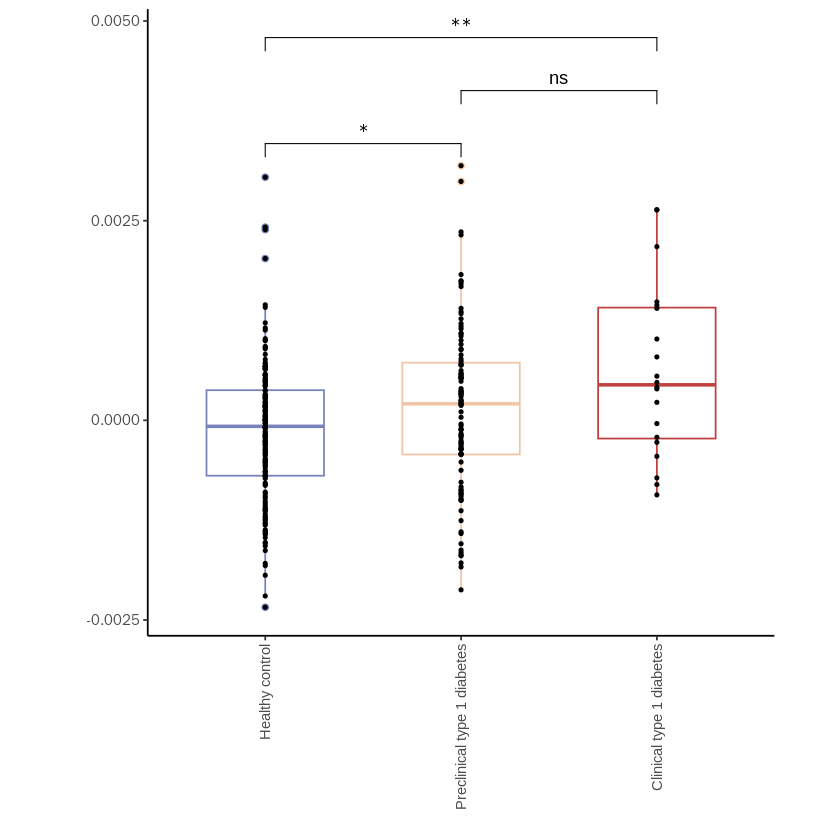

In [23]:
p <- ggplot(sd, aes(factor(group), score, color = factor(group))) +
  geom_boxplot(position = position_dodge(width = 0.75), width = 0.6)+
geom_jitter(width = 0, alpha = 1, size = 0.8,color = 'black')+
theme_classic()+scale_color_manual(values = c('#7883BA','#F2C5A7','#C04140'))+
theme(aspect.ratio = 1,panel.grid = element_blank(),
       axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1),
    legend.position = "none",
  )+labs(x = '',y='')+stat_compare_means(comparisons = list(c('Healthy control','Preclinical type 1 diabetes'),
                                                            c('Preclinical type 1 diabetes','Clinical type 1 diabetes'),
                                                            c('Healthy control','Clinical type 1 diabetes')
                                                            ),
                                         
                       method = "t.test", label = "p.signif")
p

# teplizumab cohort

In [24]:
df <- read.table('GSE85531_combined_ABATE_raw_counts_after_qc_063016_not_collapsed.txt',header = TRUE,row.names = 1)
gene_anno = data.frame(fread('Human.GRCh38.p13.annot.csv'))
gene_anno = gene_anno[gene_anno$EnsemblGeneID %in% rownames(df),]
gene_anno = gene_anno[!duplicated(gene_anno$EnsemblGeneID),]
rownames(gene_anno) = gene_anno$EnsemblGeneID
df = df[rownames(gene_anno),]
rownames(df) = gene_anno$Symbol

meta = read.csv('SraRunTable.csv')
rownames(meta) = meta$samplelabel

In [26]:
df2 = df[rownames(meta[meta$status %in% c('R','NR') & meta$visitmonth %in% c(0,6),])]
qc = df2
x <- cpm(qc, log = TRUE, prior.count = 1)
x <- t(scale(t(x)))

re <- intersect(eg, rownames(qc))

X = x[re,]*eg_df[re,]$weight
X <- as.matrix(t(X))
score <- rowMeans(X, na.rm=TRUE)
sd = data.frame(score)
sd = cbind(sd,meta[rownames(sd),])

re_itn = sd[sd$visitmonth ==0,]$itn_name
sd = sd[sd$itn_name %in% re_itn,]

In [27]:
sd$visitmonth = as.character(sd$visitmonth)

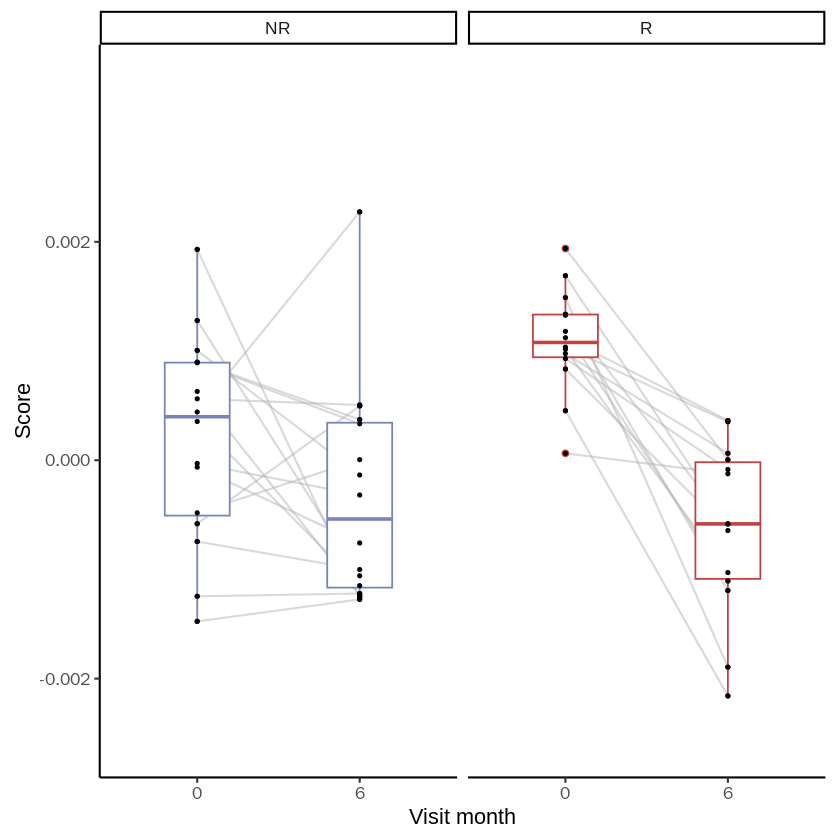

In [28]:
p2 <- ggplot(sd, aes(x = visitmonth, y = score, color = status)) +
  geom_line(aes(group = itn_name),
            alpha = 0.5, linewidth = 0.6, color = "#B4B4B4") +
  geom_point(size = 0.8, color = "black") +
  geom_boxplot(
    aes(group = visitmonth,color = status),
    fill = "white", 
    width = 0.4, 
  ) +
geom_jitter(width = 0, alpha = 1, size = 0.8,color = 'black')+
  facet_wrap(~ status) +
  theme_classic(base_size = 13) +
scale_color_manual(values = c("NR" = '#7883BA', "R" = '#C04140')) +
  labs(x = "Visit month", y = "Score") +
  theme(aspect.ratio = 2.05,legend.position = 'none',
    panel.grid = element_blank()
  )+ylim(c(-0.0026,0.0035))
p2